In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Set overall seaborn theme
sns.set_theme(style="whitegrid")

# Load the dataset
df = pd.read_csv("indian_banking_transactions.csv")

print("Seaborn environment ready. Loaded records:", len(df))

Seaborn environment ready. Loaded records: 550000


C:\Users\Samsung\AppData\Local\Temp\ipykernel_3868\1207710740.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="is_fraud", palette="pastel")


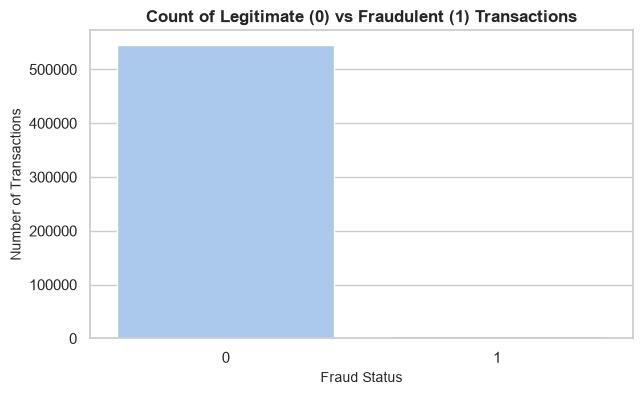

In [2]:
# Show distribution of target class: is_fraud (0 = Legitimate, 1 = Fraud)
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="is_fraud", palette="pastel")
plt.title(
    "Count of Legitimate (0) vs Fraudulent (1) Transactions",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Fraud Status", fontsize=10)
plt.ylabel("Number of Transactions", fontsize=10)
plt.show()

C:\Users\Samsung\AppData\Local\Temp\ipykernel_3868\1227381858.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


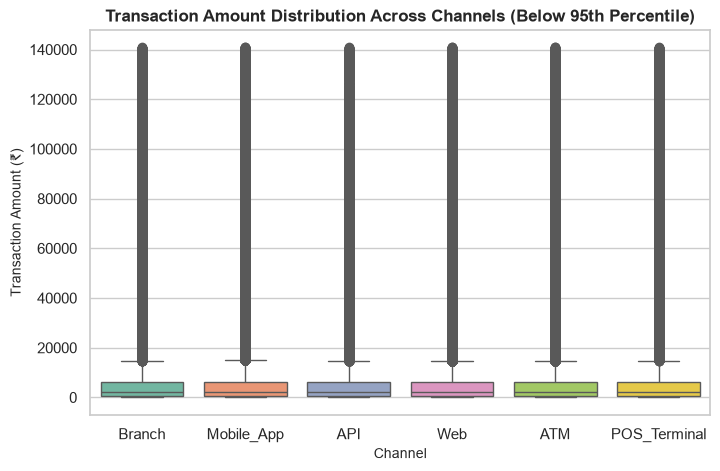

In [3]:
# Filter extreme outliers using 95th percentile so the boxes and medians are clearly visible
p95 = df["transaction_amount"].quantile(0.95)
df_filtered = df[df["transaction_amount"] <= p95]

plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df_filtered,
    x="channel",
    y="transaction_amount",
    palette="Set2",
)
plt.title(
    "Transaction Amount Distribution Across Channels (Below 95th Percentile)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Channel", fontsize=10)
plt.ylabel("Transaction Amount (₹)", fontsize=10)
plt.show()

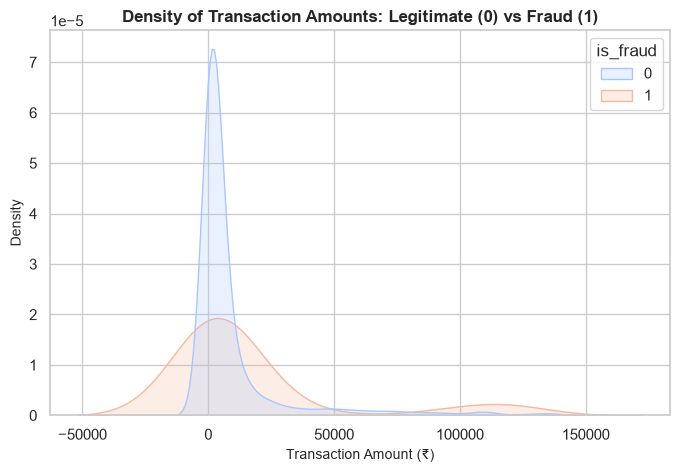

In [4]:
# Compare probability density of amounts for fraud vs legitimate
sample_df = df[df["transaction_amount"] <= p95].sample(n=5000, random_state=42)

plt.figure(figsize=(8, 5))
sns.kdeplot(
    data=sample_df,
    x="transaction_amount",
    hue="is_fraud",
    common_norm=False,
    fill=True,
    palette="coolwarm",
)
plt.title(
    "Density of Transaction Amounts: Legitimate (0) vs Fraud (1)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Transaction Amount (₹)", fontsize=10)
plt.ylabel("Density", fontsize=10)
plt.show()

C:\Users\Samsung\AppData\Local\Temp\ipykernel_3868\3744322699.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


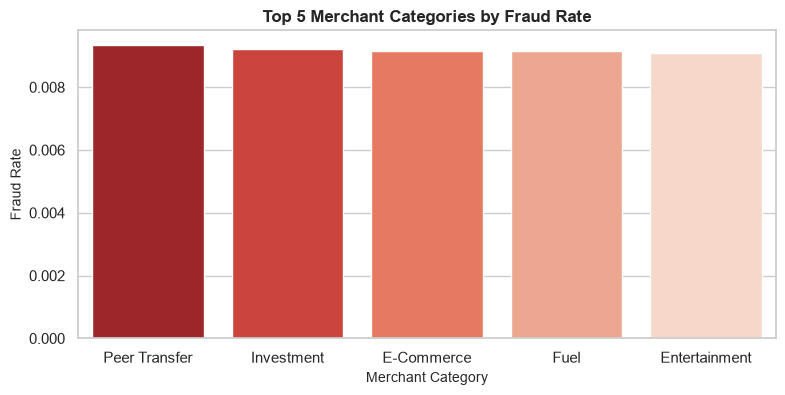

In [5]:
# Calculate fraud rate per merchant category
fraud_by_category = (
    df.groupby("merchant_category")["is_fraud"]
    .mean()
    .reset_index()
    .sort_values(by="is_fraud", ascending=False)
)

plt.figure(figsize=(9, 4))
sns.barplot(
    data=fraud_by_category.head(5),
    x="merchant_category",
    y="is_fraud",
    palette="Reds_r",
)
plt.title(
    "Top 5 Merchant Categories by Fraud Rate", fontsize=12, fontweight="bold"
)
plt.xlabel("Merchant Category", fontsize=10)
plt.ylabel("Fraud Rate", fontsize=10)
plt.show()

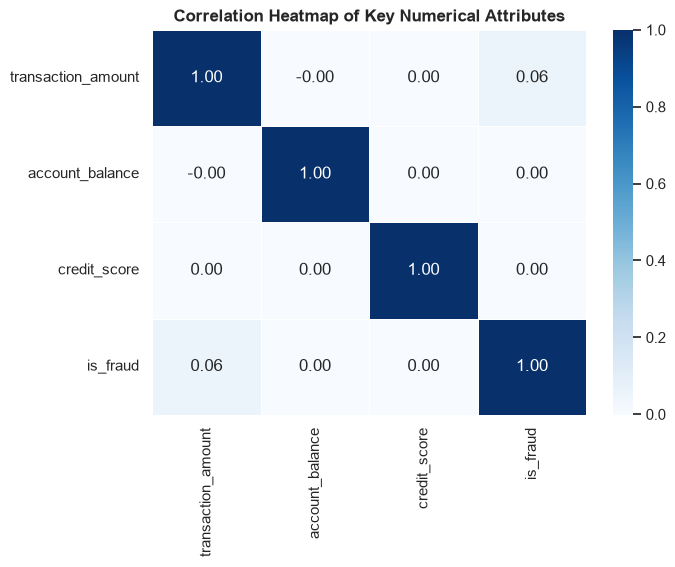

In [6]:
# Select core numerical columns
num_cols = ["transaction_amount", "account_balance", "credit_score", "is_fraud"]
corr_matrix = df[num_cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, cmap="Blues", fmt=".2f", linewidths=0.5)
plt.title(
    "Correlation Heatmap of Key Numerical Attributes",
    fontsize=12,
    fontweight="bold",
)
plt.show()